# 07 — Incremental Slimming–Fattening Ensemble (ISFE)

## Objective
Implement an abstract-guided ISFE ensemble for
imbalanced classification.

## Implementation stages

1. Load the selected ISFR feature representation.
2. Cluster the majority class.
3. Perform cluster-based majority-class undersampling.
4. Construct multiple rebalanced training subsets.
5. Train multiple base classifiers.
6. Combine predictions through majority voting.
7. Evaluate the final ensemble.

## Research limitation
The available paper abstract does not disclose the exact
clustering algorithm, undersampling ratio, or ensemble
configuration. The choices in this notebook are documented
engineering adaptations, not an exact reproduction.

In [1]:
# Cell 2 — Import libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

from sklearn.cluster import MiniBatchKMeans
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    confusion_matrix,
    classification_report
)

from sklearn.model_selection import train_test_split

import joblib
import time
import warnings

warnings.filterwarnings("ignore")

RANDOM_STATE = 42

sns.set_theme(style="whitegrid")

print("ISFE libraries imported successfully.")

ISFE libraries imported successfully.


In [2]:
# Cell 3 — Project directories

PROJECT_DIR = Path("..")

PROCESSED_DIR = PROJECT_DIR / "data" / "processed"
ISFR_DIR = PROCESSED_DIR / "isfr"

MODEL_DIR = PROJECT_DIR / "models"
REPORT_DIR = PROJECT_DIR / "reports"
FIGURE_DIR = PROJECT_DIR / "figures"

for directory in [
    MODEL_DIR,
    REPORT_DIR,
    FIGURE_DIR
]:
    directory.mkdir(parents=True, exist_ok=True)

print("ISFE directories configured.")

ISFE directories configured.


In [3]:
# Cell 4 — Load selected feature representation

X_train_isfr = np.load(
    ISFR_DIR / "View_1_Slimmed_train.npy"
)

X_val_isfr = np.load(
    ISFR_DIR / "View_1_Slimmed_validation.npy"
)

y_train = pd.read_csv(
    PROCESSED_DIR / "y_train.csv"
)["Class"].to_numpy()

y_val = pd.read_csv(
    PROCESSED_DIR / "y_val.csv"
)["Class"].to_numpy()

print("Training features:", X_train_isfr.shape)
print("Validation features:", X_val_isfr.shape)

print("Training fraud cases:", int(y_train.sum()))
print("Validation fraud cases:", int(y_val.sum()))

Training features: (182276, 27)
Validation features: (45570, 27)
Training fraud cases: 315
Validation fraud cases: 79


In [4]:
# Cell 5 — Integrity checks

assert X_train_isfr.shape == (182276, 27)
assert X_val_isfr.shape == (45570, 27)

assert len(X_train_isfr) == len(y_train)
assert len(X_val_isfr) == len(y_val)

assert np.isfinite(X_train_isfr).all()
assert np.isfinite(X_val_isfr).all()

assert set(np.unique(y_train)) == {0, 1}
assert set(np.unique(y_val)) == {0, 1}

print("ISFE input verification passed.")

ISFE input verification passed.


In [5]:
# Cell 6 — Separate the two classes

majority_mask = y_train == 0
minority_mask = y_train == 1

X_majority = X_train_isfr[majority_mask]
X_minority = X_train_isfr[minority_mask]

y_majority = y_train[majority_mask]
y_minority = y_train[minority_mask]

print("Majority samples:", len(X_majority))
print("Minority samples:", len(X_minority))

print(
    "Original imbalance ratio:",
    round(len(X_majority) / len(X_minority), 2),
    ": 1"
)

Majority samples: 181961
Minority samples: 315
Original imbalance ratio: 577.65 : 1


In [6]:
# Cell 7 — Cluster majority-class samples

n_clusters = 10

cluster_model = MiniBatchKMeans(
    n_clusters=n_clusters,
    random_state=RANDOM_STATE,
    batch_size=4096,
    n_init=3
)

majority_cluster_labels = cluster_model.fit_predict(
    X_majority
)

cluster_counts = pd.Series(
    majority_cluster_labels
).value_counts().sort_index()

print("Majority-class clustering completed.")
print("\nSamples per cluster:")
print(cluster_counts)

Majority-class clustering completed.

Samples per cluster:
0     9224
1    44309
2    19883
3    10679
4     8472
5    18434
6    24399
7    18306
8    26910
9     1345
Name: count, dtype: int64


In [7]:
# Cell 8 — Cluster-proportional majority sampling

def sample_majority_by_cluster(
    X,
    cluster_labels,
    target_count,
    random_state
):
    rng = np.random.default_rng(random_state)

    cluster_ids, cluster_sizes = np.unique(
        cluster_labels,
        return_counts=True
    )

    # Allocate the requested sample count proportionally
    exact_allocations = (
        cluster_sizes / cluster_sizes.sum()
    ) * target_count

    allocations = np.floor(exact_allocations).astype(int)

    # Distribute remaining samples using largest remainders
    remaining = target_count - allocations.sum()

    remainders = exact_allocations - allocations

    for index in np.argsort(-remainders)[:remaining]:
        allocations[index] += 1

    selected_indices = []

    for cluster_id, allocation in zip(
        cluster_ids, allocations
    ):
        candidates = np.flatnonzero(
            cluster_labels == cluster_id
        )

        chosen = rng.choice(
            candidates,
            size=allocation,
            replace=False
        )

        selected_indices.extend(chosen)

    selected_indices = np.asarray(selected_indices)

    return X[selected_indices]


target_majority_count = 3 * len(X_minority)

print("Target majority samples:", target_majority_count)
print("Target minority samples:", len(X_minority))

Target majority samples: 945
Target minority samples: 315


In [8]:
# Cell 9 — Generate independent rebalanced subsets

def create_rebalanced_subset(random_state):

    X_sampled_majority = sample_majority_by_cluster(
        X_majority,
        majority_cluster_labels,
        target_majority_count,
        random_state
    )

    X_subset = np.concatenate(
        [X_sampled_majority, X_minority],
        axis=0
    )

    y_subset = np.concatenate([
        np.zeros(len(X_sampled_majority), dtype=int),
        np.ones(len(X_minority), dtype=int)
    ])

    # Shuffle samples
    rng = np.random.default_rng(random_state)

    indices = rng.permutation(len(y_subset))

    return X_subset[indices], y_subset[indices]


rebalanced_subsets = {}

for i in range(3):

    X_subset, y_subset = create_rebalanced_subset(
        RANDOM_STATE + i
    )

    rebalanced_subsets[f"Subset_{i+1}"] = (
        X_subset,
        y_subset
    )

    print(
        f"Subset {i+1}:",
        X_subset.shape,
        "| Class counts:",
        np.bincount(y_subset)
    )

Subset 1: (1260, 27) | Class counts: [945 315]
Subset 2: (1260, 27) | Class counts: [945 315]
Subset 3: (1260, 27) | Class counts: [945 315]


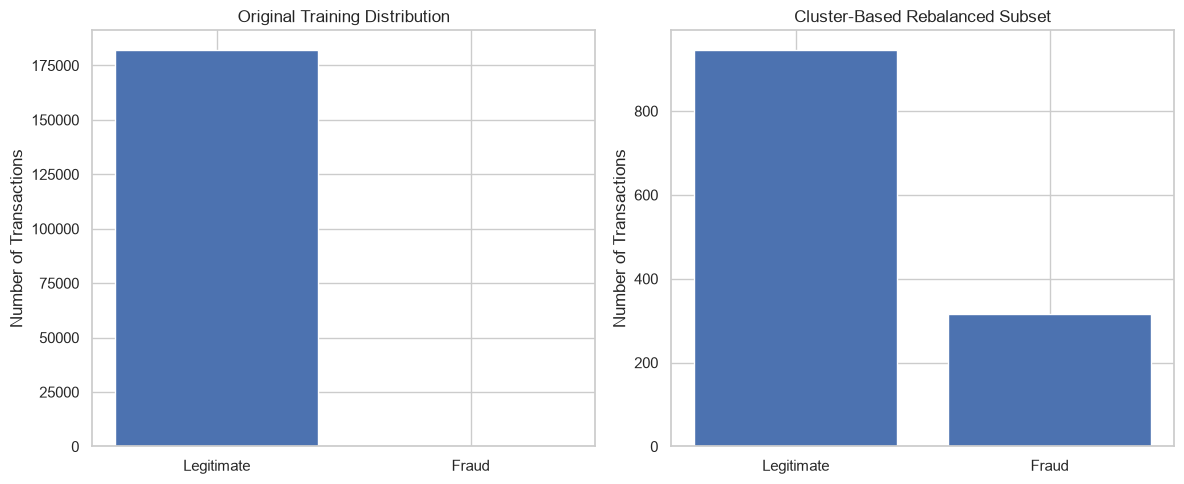

In [9]:
# Cell 10 — Compare original and rebalanced distributions

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

original_counts = pd.Series(y_train).value_counts().sort_index()

axes[0].bar(
    ["Legitimate", "Fraud"],
    original_counts.values
)
axes[0].set_title("Original Training Distribution")
axes[0].set_ylabel("Number of Transactions")

balanced_counts = np.bincount(
    rebalanced_subsets["Subset_1"][1]
)

axes[1].bar(
    ["Legitimate", "Fraud"],
    balanced_counts
)
axes[1].set_title("Cluster-Based Rebalanced Subset")
axes[1].set_ylabel("Number of Transactions")

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "isfe_class_distribution.png",
    dpi=300
)

plt.show()

In [10]:
# Cell 11 — Train three Random Forest classifiers

isfe_models = {}
isfe_training_times = {}

for name, (X_subset, y_subset) in rebalanced_subsets.items():

    print(f"\nTraining {name}...")

    model = RandomForestClassifier(
        n_estimators=200,
        class_weight=None,
        random_state=RANDOM_STATE,
        n_jobs=-1
    )

    start = time.time()

    model.fit(X_subset, y_subset)

    elapsed = time.time() - start

    isfe_models[name] = model
    isfe_training_times[name] = elapsed

    print("Training time:", round(elapsed, 2), "seconds")

print("\nAll ISFE base classifiers trained.")


Training Subset_1...
Training time: 0.76 seconds

Training Subset_2...
Training time: 0.58 seconds

Training Subset_3...
Training time: 0.55 seconds

All ISFE base classifiers trained.


In [11]:
# Cell 12 — Generate validation predictions

isfe_predictions = {}

for name, model in isfe_models.items():

    isfe_predictions[name] = model.predict(X_val_isfr)

    print(name, "predictions generated.")

Subset_1 predictions generated.
Subset_2 predictions generated.
Subset_3 predictions generated.


In [12]:
# Cell 13 — Hard voting

prediction_matrix = np.column_stack(
    list(isfe_predictions.values())
)

isfe_final_predictions = (
    prediction_matrix.sum(axis=1) >= 2
).astype(int)

print("Final ISFE ensemble predictions generated.")

print(
    "Predicted legitimate:",
    int((isfe_final_predictions == 0).sum())
)

print(
    "Predicted fraud:",
    int((isfe_final_predictions == 1).sum())
)

Final ISFE ensemble predictions generated.
Predicted legitimate: 45033
Predicted fraud: 537


In [13]:
# Cell 14 — Evaluate the final ensemble

isfe_results = {
    "Model": "ISFE Adapted Ensemble",

    "Accuracy": accuracy_score(
        y_val, isfe_final_predictions
    ),

    "Macro F1": f1_score(
        y_val,
        isfe_final_predictions,
        average="macro",
        zero_division=0
    ),

    "Balanced Accuracy": balanced_accuracy_score(
        y_val, isfe_final_predictions
    ),

    "Fraud Precision": precision_score(
        y_val,
        isfe_final_predictions,
        zero_division=0
    ),

    "Fraud Recall": recall_score(
        y_val,
        isfe_final_predictions,
        zero_division=0
    ),

    "Fraud F1": f1_score(
        y_val,
        isfe_final_predictions,
        zero_division=0
    ),

    "Total Training Time (s)": sum(
        isfe_training_times.values()
    )
}

isfe_results_df = pd.DataFrame([isfe_results])

display(isfe_results_df.round(4))

,Model,Accuracy,Macro F1,Balanced Accuracy,Fraud Precision,Fraud Recall,Fraud F1,Total Training Time (s)
0,ISFE Adapted Ensemble,0.9897,0.6159,0.9569,0.1359,0.9241,0.237,1.8912


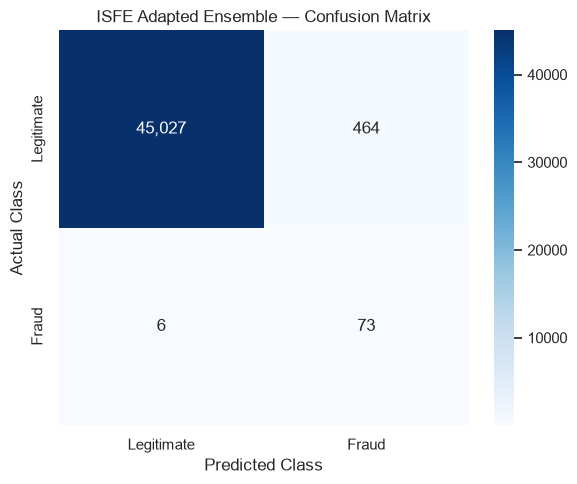

In [14]:
# Cell 15 — ISFE confusion matrix

cm = confusion_matrix(
    y_val,
    isfe_final_predictions
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt=",",
    cmap="Blues",
    xticklabels=["Legitimate", "Fraud"],
    yticklabels=["Legitimate", "Fraud"]
)

plt.title("ISFE Adapted Ensemble — Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "isfe_confusion_matrix.png",
    dpi=300
)

plt.show()

In [15]:
# Cell 16 — Save models and experiment results

isfe_results_df.to_csv(
    REPORT_DIR / "isfe_results.csv",
    index=False
)

for name, model in isfe_models.items():

    joblib.dump(
        model,
        MODEL_DIR / f"{name.lower()}_isfe.joblib"
    )

joblib.dump(
    cluster_model,
    MODEL_DIR / "isfe_cluster_model.joblib"
)

print("ISFE models and results saved.")

ISFE models and results saved.
